# ConvNeXt-Tiny — CIFAR-100



### Cấu hình TRAIN / LOAD — cell bổ sung


In [1]:
# Chỉ sửa các dòng cấu hình cần thiết. DATA_DIR giữ đúng đường dẫn ban đầu.
RUN_MODE = "TRAIN"                  # "TRAIN" hoặc "LOAD"
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"
BUNDLE_PATH = ""                    # LOAD: ZIP phân tích/kho mọi epoch hoặc thư mục đã giải nén
OUTPUT_ROOT = "/kaggle/working/cifar100_unified"
SPLIT_SCHEME = "45k_5k_10k"          # Mặc định; lựa chọn khác: "50k_5k_5k"
SHARED_SPLIT_PATH = ""              # Tùy chọn: dùng chính split_indices.npz của notebook còn lại
SEED = 42
RUN_FULL_TSNE = True                # Toàn bộ Test; có thể tắt để xem nhanh các phần khác
RUN_DETAIL_TSNE = True              # Hình chi tiết các lớp bên dưới
TSNE_CLASS_IDS = list(range(10))
TSNE_PER_CLASS = 100                # Tự giảm nếu Test mỗi lớp có ít hơn 100 ảnh
TSNE_MAX_ITER = 1000
MODEL_KEY = "convnext_tiny"
MODEL_NAME = "ConvNeXt-Tiny"
BEST_FILENAME = "best.pth"
INPUT_SIZE = 224
FEATURE_DIM = 768
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS_HEAD = 5
EPOCHS_FINE_TUNE = 5
HEAD_LR = 0.001
FINE_TUNE_LR = 0.00001
LOSS_DESCRIPTION = "Cross-entropy with label_smoothing=0.1"


## 1. Khởi tạo thư viện & Thiết bị (Device)


In [2]:
import os
import copy
import pickle
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms.v2 as transforms
import torchvision.models as models
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


### Thư viện phụ trợ cho lưu và nạp — không đổi cách khởi tạo thiết bị


In [3]:
import os
import json
import pickle
import time
import random
import shutil
import hashlib
import inspect
import platform
import uuid
import zipfile
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata as package_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, ListedColormap, BoundaryNorm
from matplotlib.ticker import MaxNLocator
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

try:
    from IPython.display import display, FileLink
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)
    FileLink = None

SCHEMA_VERSION = "cifar100_unified_v1"
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 13, "axes.labelsize": 11,
                     "figure.dpi": 110, "savefig.dpi": 300})


In [4]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
EVALUATION_DEVICE = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"


In [5]:
def backend_details():
    return {"framework": "PyTorch/Torchvision", "torch_version": torch.__version__,
            "torchvision_version": torchvision.__version__, "train_device": EVALUATION_DEVICE,
            "training": {"epochs_head": EPOCHS_HEAD, "epochs_fine_tune": EPOCHS_FINE_TUNE,
                         "head_lr": HEAD_LR, "fine_tune_lr": FINE_TUNE_LR},
            "preprocessing": {"input_size": 224, "mean": [0.485, 0.456, 0.406],
                              "std": [0.229, 0.224, 0.225], "rotation_degrees": 10,
                              "train_augmentation": ["horizontal_flip", "random_resized_crop", "rotation", "color_jitter"]},
            "label_smoothing": 0.1}


### Ghi cấu hình JSON


In [6]:
def json_write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


In [7]:
def json_read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


### Kiểm tra tệp và phiên bản


In [8]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


In [9]:
def installed_version(name):
    try:
        return package_metadata.version(name)
    except package_metadata.PackageNotFoundError:
        return "unknown"


In [10]:
def file_links(paths):
    for path in map(Path, paths):
        if not path.is_file():
            continue
        print(f"{path.name}: {path.stat().st_size / (1024 ** 2):.2f} MiB")
        if FileLink is not None:
            display(FileLink(str(path)))
        else:
            print(path)


### Chia tập phân tầng


In [11]:
def stratified_split(labels, validation_fraction, seed):
    rng = np.random.default_rng(seed)
    train, validation = [], []
    for class_id in np.unique(labels):
        ids = rng.permutation(np.flatnonzero(labels == class_id))
        if len(ids) < 2:
            raise ValueError("Mỗi lớp cần ít nhất 2 ảnh để tách Train và Validation.")
        n_validation = min(len(ids) - 1, max(1, int(round(len(ids) * validation_fraction))))
        validation.extend(ids[:n_validation].tolist())
        train.extend(ids[n_validation:].tolist())
    train, validation = np.asarray(train, dtype=np.int64), np.asarray(validation, dtype=np.int64)
    rng.shuffle(train)
    rng.shuffle(validation)
    return train, validation


In [12]:
def create_splits(labels, original_train_count, scheme, seed):
    if scheme == "45k_5k_10k":
        train, validation = stratified_split(labels[:original_train_count], 0.1, seed)
        test = np.arange(original_train_count, len(labels), dtype=np.int64)
    elif scheme == "50k_5k_5k":
        validation_local, test_local = stratified_split(labels[original_train_count:], 0.5, seed)
        train = np.arange(original_train_count, dtype=np.int64)
        validation = validation_local + original_train_count
        test = test_local + original_train_count
    else:
        raise ValueError("SPLIT_SCHEME phải là '45k_5k_10k' hoặc '50k_5k_5k'.")
    return {"train_idx": train, "val_idx": validation, "test_idx": test}


In [13]:
def validate_splits(splits, count):
    arrays = [np.asarray(splits[key], dtype=np.int64) for key in ("train_idx", "val_idx", "test_idx")]
    joined = np.concatenate(arrays)
    if any(len(array) == 0 for array in arrays):
        raise ValueError("Train/Validation/Test không được rỗng.")
    if np.any(joined < 0) or np.any(joined >= count) or len(np.unique(joined)) != len(joined):
        raise ValueError("Chỉ số chia tập không hợp lệ hoặc có ảnh trùng giữa các tập.")
    if len(joined) != count:
        raise ValueError("Danh sách chia tập chưa bao phủ toàn bộ dữ liệu.")


### Nhận diện danh sách ảnh và lần chạy


In [14]:
def split_signature(splits, dataset_digest):
    digest = hashlib.sha256(dataset_digest.encode("ascii"))
    for key in ("train_idx", "val_idx", "test_idx"):
        digest.update(key.encode("ascii"))
        digest.update(np.asarray(splits[key], dtype="<i8").tobytes())
    return digest.hexdigest()


In [15]:
def new_run_directory(prefix):
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    directory = Path(OUTPUT_ROOT) / f"{prefix}_{stamp}_{uuid.uuid4().hex[:6]}"
    directory.mkdir(parents=True, exist_ok=False)
    return directory


In [16]:
def visual_indices(labels, test_idx, seed):
    rng = np.random.default_rng(seed)
    test_labels = labels[test_idx]
    details = []
    for class_id in TSNE_CLASS_IDS:
        positions = np.flatnonzero(test_labels == class_id)
        if len(positions):
            details.extend(rng.choice(positions, size=min(TSNE_PER_CLASS, len(positions)), replace=False).tolist())
    predictions = rng.choice(len(test_idx), size=min(30, len(test_idx)), replace=False)
    return {"prediction_positions": np.asarray(predictions, dtype=np.int64),
            "tsne_detail_positions": np.asarray(details, dtype=np.int64),
            "feature_map_position": np.asarray(0, dtype=np.int64)}


### Đọc bộ tệp đã tải lên


In [17]:
def resolve_bundle(source, destination):
    source = Path(source).expanduser()
    if not source.exists():
        raise FileNotFoundError(f"Không tìm thấy BUNDLE_PATH: {source}")
    if source.is_file():
        if source.suffix.lower() != ".zip":
            raise ValueError("BUNDLE_PATH cần trỏ tới ZIP phân tích hoặc thư mục đã giải nén, không chỉ riêng tệp trọng số.")
        extracted = destination / "_bundle_input"
        extracted.mkdir()
        with zipfile.ZipFile(source) as archive:
            for item in archive.infolist():
                target = (extracted / item.filename).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError("ZIP chứa đường dẫn nằm ngoài thư mục giải nén.")
            archive.extractall(extracted)
        source = extracted
    candidates = list(source.rglob("config.json"))
    if len(candidates) != 1:
        raise ValueError("Thư mục/ZIP phải chứa đúng một config.json của một lần chạy.")
    return candidates[0].parent


In [18]:
mode = RUN_MODE.upper()
if mode not in ("TRAIN", "LOAD"):
    raise ValueError("RUN_MODE chỉ nhận TRAIN hoặc LOAD.")
run_dir = new_run_directory(MODEL_KEY if mode == "TRAIN" else MODEL_KEY + "_loaded")
ANALYSIS_READY = False
analysis_dir = None
selected_info = None
history_df = pd.DataFrame()
if mode == "TRAIN":
    checkpoint_root = run_dir / "checkpoints"
    checkpoint_root.mkdir()
else:
    if not BUNDLE_PATH:
        raise ValueError("LOAD cần điền BUNDLE_PATH; không tự train lại khi thiếu mô hình.")
    bundle_source = resolve_bundle(BUNDLE_PATH, run_dir)
    for name in ("config.json", "history.csv", "split_indices.npz", "visual_indices.npz"):
        if not (bundle_source / name).is_file():
            raise FileNotFoundError(f"Thiếu {name} trong bộ tệp đã tải lên.")
        shutil.copy2(bundle_source / name, run_dir / name)
    run_config = json_read(run_dir / "config.json")
    if run_config.get("model_key") != MODEL_KEY or run_config.get("schema_version") != SCHEMA_VERSION:
        raise ValueError("Bộ tệp không đúng mô hình/phiên bản notebook.")
    if run_config["feature_dim"] != FEATURE_DIM or run_config["input_size"] != INPUT_SIZE:
        raise ValueError("Checkpoint khác kiến trúc gốc: CNN 256D/32x32, ConvNeXt 768D/224x224.")
    history_df = pd.read_csv(run_dir / "history.csv")
    checkpoint_root = bundle_source / "checkpoints"
    if (bundle_source / BEST_FILENAME).is_file() and (bundle_source / "selection.json").is_file():
        for name in (BEST_FILENAME, "selection.json"):
            shutil.copy2(bundle_source / name, run_dir / name)
        selected_info = json_read(run_dir / "selection.json")
        if sha256_file(run_dir / BEST_FILENAME) != selected_info["checkpoint_sha256"]:
            raise ValueError("Checkpoint không khớp selection.json.")
    elif not checkpoint_root.is_dir():
        raise FileNotFoundError("Thiếu best/selection.json hoặc kho checkpoints.")
print("Kết quả:", run_dir)


Kết quả: /kaggle/working/cifar100_unified/convnext_tiny_20261023T133653Z_1f8ef0


## 2. Tải Mô hình ConvNeXt Pretrained (ImageNet)


In [19]:
# Tải mô hình ConvNeXt-Tiny kèm bộ trọng số ImageNet-1K chính thức (weights=DEFAULT)
weights = models.ConvNeXt_Tiny_Weights.DEFAULT
convnext_model = models.convnext_tiny(weights=weights if mode == "TRAIN" else None)
print("Pretrained ConvNeXt-Tiny loaded successfully!")


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 213MB/s]  


Pretrained ConvNeXt-Tiny loaded successfully!


In [20]:
print(convnext_model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

## 3. Freeze Base Model (Đóng băng đặc trưng đã học từ ImageNet)


In [21]:
# Đóng băng toàn bộ phần backbone features
convnext_model.requires_grad_(False)
print("Base model frozen:", not next(iter(convnext_model.features.parameters())).requires_grad)

Base model frozen: True


## 4. Thay thế lớp Classifier (Cắt lớp 1000 neuron ImageNet thay bằng 100 lớp CIFAR-100)


In [22]:
# Bộ dữ liệu CIFAR-100 gồm 100 lớp
N_CLASSES = 100

# Trong ConvNeXt, classifier[2] là Linear(768, 1000)
# Ta thay bằng Linear(768, N_CLASSES)
convnext_model.classifier[2] = nn.Linear(768, N_CLASSES)
convnext_model = convnext_model.to(device)
print(convnext_model.classifier)


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=100, bias=True)
)


In [23]:
print(convnext_model)

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

## 5. Cấu hình Loss, Optimizer & Data Transforms (Kèm transforms.Resize 224x224)


In [24]:
# Loss function với Label Smoothing nhẹ để chống overfitting trên 100 lớp
loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = Adam(convnext_model.classifier[2].parameters(), lr=HEAD_LR)

pre_trans = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_trans = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop((224,224),scale=(0.75,1.0),interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3,contrast=0.3,saturation=0.2),
    transforms.ToImage(),transforms.ToDtype(torch.float32,scale=True),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])


## 6. Nạp Dữ liệu CIFAR-100 (fedesoriano/cifar100) & Khởi tạo DataLoader


In [25]:
# --- CELL 6: NẠP DỮ LIỆU CIFAR-100 ---
# Danh sách chuẩn 100 lớp của CIFAR-100
CIFAR100_CLASSES = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 
    'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 
    'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 
    'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 
    'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 
    'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

class CIFAR100PickleDataset(Dataset):
    """Dataset nạp trực tiếp file pickle train/test từ fedesoriano/cifar100 trên Kaggle"""
    def __init__(self, file_path, transform=None):
        self.transform = transform
        with open(file_path, 'rb') as f:
            entry = pickle.load(f, encoding='latin1')
        
        # Reshape (N, 3072) -> (N, 3, 32, 32) -> (N, 32, 32, 3) RGB uint8
        raw_data = entry['data']
        self.data = raw_data.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        # Lấy nhãn 100 lớp (fine_labels)
        self.targets = entry.get('fine_labels', entry.get('labels', []))
        self.classes = CIFAR100_CLASSES

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_arr = self.data[idx]
        img = Image.fromarray(img_arr)
        target = self.targets[idx]
        if self.transform:
            img = self.transform(img)
        return img, target

# Đường dẫn cố định theo bộ dữ liệu của bạn trên Kaggle
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"
TRAIN_FILE = os.path.join(DATA_DIR, "train")
TEST_FILE = os.path.join(DATA_DIR, "test")

train_data = CIFAR100PickleDataset(TRAIN_FILE,transform=train_trans)
test_data = CIFAR100PickleDataset(TEST_FILE,transform=pre_trans)
x_train,y_train = train_data.data,np.asarray(train_data.targets)
x_test,y_test = test_data.data,np.asarray(test_data.targets)
class_names = CIFAR100_CLASSES


In [26]:
# Dùng ảnh gốc của các cell đọc dữ liệu, không thay đường dẫn dataset.
raw_images = np.ascontiguousarray(np.concatenate([x_train, x_test], axis=0))
raw_labels = np.concatenate([np.asarray(y_train, dtype=np.int64), np.asarray(y_test, dtype=np.int64)])
original_train_count = len(x_train)
digest = hashlib.sha256()
digest.update(memoryview(raw_images))
digest.update(raw_labels.astype("<i8").tobytes())
digest.update(json.dumps(class_names, ensure_ascii=False).encode("utf-8"))
dataset_digest = digest.hexdigest()
if mode == "TRAIN":
    if SHARED_SPLIT_PATH:
        with np.load(SHARED_SPLIT_PATH, allow_pickle=False) as saved:
            if str(saved["dataset_sha256"].item()) != dataset_digest or str(saved["split_scheme"].item()) != SPLIT_SCHEME:
                raise ValueError("Tệp chia tập dùng chung không khớp dataset/cách chia.")
            splits = {key:saved[key].astype(np.int64) for key in ("train_idx","val_idx","test_idx")}
    else:
        splits = create_splits(raw_labels, original_train_count, SPLIT_SCHEME, SEED)
    validate_splits(splits, len(raw_labels))
    np.savez_compressed(run_dir / "split_indices.npz", **splits,
                        dataset_sha256=np.asarray(dataset_digest), split_scheme=np.asarray(SPLIT_SCHEME))
    visual_samples = visual_indices(raw_labels, splits["test_idx"], SEED)
    np.savez_compressed(run_dir / "visual_indices.npz", **visual_samples)
else:
    if run_config["dataset_sha256"] != dataset_digest or run_config["class_names"] != class_names:
        raise ValueError("Dataset hoặc thứ tự tên lớp khác lần train.")
    with np.load(run_dir / "split_indices.npz", allow_pickle=False) as saved:
        splits = {key:saved[key].astype(np.int64) for key in ("train_idx","val_idx","test_idx")}
    validate_splits(splits, len(raw_labels))
    if split_signature(splits, dataset_digest) != run_config["split_signature"]:
        raise ValueError("Danh sách chia tập khác config.json.")
    with np.load(run_dir / "visual_indices.npz", allow_pickle=False) as saved:
        visual_samples = {key:saved[key] for key in saved.files}
display(pd.DataFrame([{"Split":label,"Images":len(splits[key])}
                      for label,key in [("Train","train_idx"),("Validation","val_idx"),("Test","test_idx")]]))
file_links([run_dir / "split_indices.npz"])


,Split,Images
0,Train,45000
1,Validation,5000
2,Test,10000


split_indices.npz: 0.15 MiB


/kaggle/working/cifar100_unified/convnext_tiny_20261023T133653Z_1f8ef0/split_indices.npz

In [27]:
if mode == "TRAIN":
    run_config = {"schema_version":SCHEMA_VERSION,"model_key":MODEL_KEY,"model_name":MODEL_NAME,
                  "seed":SEED,"split_scheme":SPLIT_SCHEME,"dataset_sha256":dataset_digest,
                  "split_signature":split_signature(splits,dataset_digest),"data_dir":DATA_DIR,
                  "class_names":class_names,"num_classes":len(class_names),"feature_dim":FEATURE_DIM,
                  "input_size":INPUT_SIZE,"batch_size":BATCH_SIZE,"loss_definition":LOSS_DESCRIPTION,
                  "run_id":run_dir.name,"python":platform.python_version(),
                  "visualization":{"tsne_class_ids":TSNE_CLASS_IDS,"tsne_per_class":TSNE_PER_CLASS,
                                   "seed":SEED,"perplexity":30,"learning_rate":200,"max_iter":TSNE_MAX_ITER},
                  **backend_details()}
    json_write(run_dir / "config.json",run_config)
pd.DataFrame({"class_id":np.arange(len(class_names)),"class_name":class_names}).to_csv(run_dir / "class_names.csv",index=False)


In [28]:
train_eval_data = copy.copy(train_data)
train_eval_data.transform = pre_trans
test_train_data = copy.copy(test_data)
test_train_data.transform = train_trans
train_all = torch.utils.data.ConcatDataset([train_data, test_train_data])
eval_all = torch.utils.data.ConcatDataset([train_eval_data, test_data])

def make_torch_loader(indices, training=False):
    subset = torch.utils.data.Subset(train_all if training else eval_all, np.asarray(indices,dtype=int).tolist())
    return DataLoader(subset,batch_size=BATCH_SIZE,shuffle=training,num_workers=NUM_WORKERS,
                      pin_memory=(device.type=="cuda"),generator=torch.Generator().manual_seed(SEED))

train_loader = make_torch_loader(splits["train_idx"],training=True)
valid_loader = make_torch_loader(splits["val_idx"])
test_loader = make_torch_loader(splits["test_idx"])


## 7a. Huấn luyện Giai đoạn 1: Train Classifier Head — lưu mọi epoch


### Ghi lịch sử mỗi epoch


In [29]:
def append_history(row):
    global history_df
    if not all(np.isfinite(row[key]) for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy")):
        raise ValueError("Loss/Accuracy không hữu hạn; dừng để không chọn checkpoint lỗi.")
    history_df = pd.concat([history_df, pd.DataFrame([row])], ignore_index=True)
    temporary = run_dir / "history.csv.tmp"
    history_df.to_csv(temporary, index=False)
    temporary.replace(run_dir / "history.csv")


In [30]:
def save_torch_epoch(epoch, phase, phase_epoch, lr, tr_loss, tr_acc, val_loss, val_acc):
    name = f"epoch_{epoch:03d}.pth"
    torch.save({"model_state_dict":{key:value.detach().cpu() for key,value in convnext_model.state_dict().items()},
                "epoch":epoch,"phase":phase,"phase_epoch":phase_epoch,"feature_dim":768,
                "num_classes":100,"val_loss":val_loss,"val_accuracy":val_acc},checkpoint_root / name)
    append_history({"epoch":epoch,"phase":phase,"phase_epoch":phase_epoch,"learning_rate":lr,
                    "train_loss":tr_loss,"train_accuracy":tr_acc,"val_loss":val_loss,"val_accuracy":val_acc,
                    "checkpoint":name})


In [31]:
if mode == "TRAIN":
    if (run_dir / "history.csv").exists():
        raise RuntimeError("Đã có lịch sử; không chạy lại cell train head. Muốn train mới, chạy lại từ đầu.")
    def train_epoch(model, loader, optimizer, loss_fn):
        model.train()
        total_loss, correct = 0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
        return total_loss / len(loader.dataset), correct / len(loader.dataset)

    def validate_epoch(model, loader, loss_fn):
        model.eval()
        total_loss, correct = 0, 0
        with torch.no_grad():
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = loss_fn(out, y)
                total_loss += loss.item() * len(y)
                correct += (out.argmax(1) == y).sum().item()
        return total_loss / len(loader.dataset), correct / len(loader.dataset)

    # Khởi tạo cấu trúc lưu lịch sử huấn luyện
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    best_val_acc = 0.0
    best_weights = copy.deepcopy(convnext_model.state_dict())

    epochs_head = EPOCHS_HEAD
    for epoch in range(1, epochs_head + 1):
        tr_loss, tr_acc = train_epoch(convnext_model, train_loader, optimizer, loss_function)
        val_loss, val_acc = validate_epoch(convnext_model, valid_loader, loss_function)
    
        # Ghi nhận vào lịch sử
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)
    
        save_torch_epoch(epoch,"head",epoch,HEAD_LR,tr_loss,tr_acc,val_loss,val_acc)
        status = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(convnext_model.state_dict())
            torch.save(best_weights, run_dir / "head_best.pth")
        
        print(f"Epoch {epoch:02d}/{epochs_head:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} {status}")

    # NẠP LẠI TRỌNG SỐ TỐT NHẤT CỦA GIAI ĐOẠN 1
    convnext_model.load_state_dict(best_weights)

else:
    print("LOAD: bỏ qua train head.")


Epoch 01/05 | Train Loss: 1.9809 Acc: 0.6523 | Val Loss: 1.5580 Acc: 0.7634 
Epoch 02/05 | Train Loss: 1.6511 Acc: 0.7366 | Val Loss: 1.5149 Acc: 0.7856 
Epoch 03/05 | Train Loss: 1.5987 Acc: 0.7566 | Val Loss: 1.5061 Acc: 0.7960 
Epoch 04/05 | Train Loss: 1.5649 Acc: 0.7691 | Val Loss: 1.4926 Acc: 0.8014 
Epoch 05/05 | Train Loss: 1.5457 Acc: 0.7767 | Val Loss: 1.5044 Acc: 0.8010 


## 7b. Huấn luyện Giai đoạn 2: Fine-Tuning Toàn Bộ Mô Hình — lưu mọi epoch


In [32]:
if mode == "TRAIN":
    if len(history_df) != EPOCHS_HEAD:
        raise RuntimeError("Fine-tune cần đủ epoch head và chưa được chạy trước đó.")
    # Mở khóa toàn bộ mô hình (Unfreeze base model)
    convnext_model.requires_grad_(True)

    # Optimizer với learning rate nhỏ để fine-tune
    optimizer_ft = Adam(convnext_model.parameters(), lr=FINE_TUNE_LR)

    epochs_ft = EPOCHS_FINE_TUNE
    for epoch in range(1, epochs_ft + 1):
        tr_loss, tr_acc = train_epoch(convnext_model, train_loader, optimizer_ft, loss_function)
        val_loss, val_acc = validate_epoch(convnext_model, valid_loader, loss_function)
    
        # Ghi nhận tiếp vào lịch sử
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)
    
        save_torch_epoch(epochs_head+epoch,"fine_tune",epoch,FINE_TUNE_LR,tr_loss,tr_acc,val_loss,val_acc)
        status = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(convnext_model.state_dict())
            torch.save(best_weights, run_dir / "fine_tune_best.pth")
        
        print(f"Fine-tune Epoch {epoch:02d}/{epochs_ft:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} {status}")

    # Nạp lại bản ghi tốt nhất tuyệt đối
    convnext_model.load_state_dict(best_weights)

else:
    print("LOAD: bỏ qua fine-tune.")


Fine-tune Epoch 01/05 | Train Loss: 1.3483 Acc: 0.8380 | Val Loss: 1.3048 Acc: 0.8498 
Fine-tune Epoch 02/05 | Train Loss: 1.2498 Acc: 0.8681 | Val Loss: 1.2622 Acc: 0.8570 
Fine-tune Epoch 03/05 | Train Loss: 1.1933 Acc: 0.8875 | Val Loss: 1.2367 Acc: 0.8668 
Fine-tune Epoch 04/05 | Train Loss: 1.1487 Acc: 0.9008 | Val Loss: 1.2216 Acc: 0.8682 
Fine-tune Epoch 05/05 | Train Loss: 1.1091 Acc: 0.9167 | Val Loss: 1.2067 Acc: 0.8746 


## 7c. Vẽ Biểu đồ Theo dõi Loss & Accuracy qua các Epochs (Train vs Val)


### Lưu hình và ghi checkpoint trên hình


In [33]:
def checkpoint_caption():
    return f"{MODEL_NAME} | epoch {int(selected_info['epoch'])} | {selected_info['phase']}"


In [34]:
def save_figure(fig, name, target=None):
    destination = Path(target or analysis_dir) / name
    fig.savefig(destination, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return destination


Các mốc tham khảo, không tự chọn thay bạn:


,Criterion,Epoch,Phase,Val Loss,Val Accuracy (%)
0,Minimum validation loss,10,fine_tune,1.2067,87.46
1,Maximum validation accuracy,10,fine_tune,1.2067,87.46


Tổng số epoch thực tế: 10. Accuracy trong bảng dưới tính bằng %.


,epoch,phase,phase_epoch,learning_rate,train_loss,train_accuracy,val_loss,val_accuracy,checkpoint
0,1,head,1,0.00100,1.98089,65.22667,1.55802,76.34,epoch_001.pth
1,2,head,2,0.00100,1.65107,73.65778,1.51494,78.56,epoch_002.pth
2,3,head,3,0.00100,1.59871,75.66444,1.50615,79.60,epoch_003.pth
3,4,head,4,0.00100,1.56486,76.91111,1.49258,80.14,epoch_004.pth
4,5,head,5,0.00100,1.54567,77.66667,1.50443,80.10,epoch_005.pth
5,6,fine_tune,1,0.00001,1.34825,83.79778,1.30484,84.98,epoch_006.pth
6,7,fine_tune,2,0.00001,1.24984,86.81333,1.26215,85.70,epoch_007.pth
7,8,fine_tune,3,0.00001,1.19333,88.74889,1.23669,86.68,epoch_008.pth
8,9,fine_tune,4,0.00001,1.14873,90.07778,1.22158,86.82,epoch_009.pth
9,10,fine_tune,5,0.00001,1.10910,91.66667,1.20669,87.46,epoch_010.pth


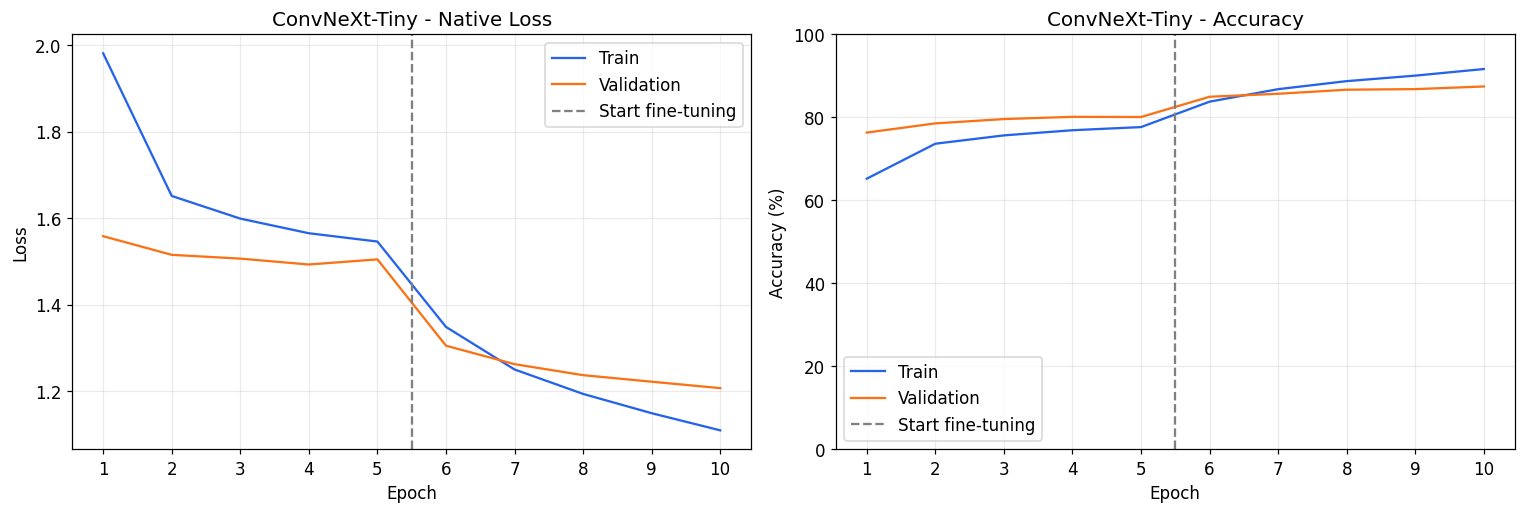

In [35]:
if not history_df.empty:
    selected_epoch = selected_info["epoch"] if selected_info else None
    frame = pd.read_csv(run_dir / "history.csv") if (run_dir / "history.csv").is_file() else history_df

    candidates = []

    for criterion, index in (("Minimum validation loss", frame["val_loss"].idxmin()),
                             ("Maximum validation accuracy", frame["val_accuracy"].idxmax())):
        row = frame.loc[index]
        candidates.append({"Criterion": criterion, "Epoch": int(row["epoch"]), "Phase": row["phase"],
                           "Val Loss": row["val_loss"], "Val Accuracy (%)": row["val_accuracy"] * 100})

    print("Các mốc tham khảo, không tự chọn thay bạn:")

    display(pd.DataFrame(candidates).round(4))

    table = frame.copy()

    table["train_accuracy"] *= 100

    table["val_accuracy"] *= 100

    print(f"Tổng số epoch thực tế: {len(frame)}. Accuracy trong bảng dưới tính bằng %.")

    display(table.round(5))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    axes[0].plot(frame["epoch"], frame["train_loss"], color="#2563eb", label="Train")

    axes[0].plot(frame["epoch"], frame["val_loss"], color="#f97316", label="Validation")

    axes[0].set(title=f"{MODEL_NAME} - Native Loss", xlabel="Epoch", ylabel="Loss")

    axes[1].plot(frame["epoch"], frame["train_accuracy"] * 100, color="#2563eb", label="Train")

    axes[1].plot(frame["epoch"], frame["val_accuracy"] * 100, color="#f97316", label="Validation")

    axes[1].set(title=f"{MODEL_NAME} - Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")

    axes[1].set_ylim(0, 100)

    changes = frame.loc[frame["phase"].ne(frame["phase"].shift())].iloc[1:]

    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        for _, row in changes.iterrows():
            ax.axvline(float(row["epoch"]) - 0.5, color="gray", linestyle="--", label="Start fine-tuning")
        if selected_epoch is not None:
            ax.axvline(int(selected_epoch), color="#7c3aed", linestyle=":", linewidth=2, label=f"Selected: {selected_epoch}")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.tight_layout()

    save_figure(fig, "training_curves.png", target=analysis_dir if analysis_dir else run_dir)


### Đóng gói và chọn checkpoint


In [36]:
SELECTED_EPOCH = 7
import json, hashlib
from IPython.display import display, FileLink

epoch_row = history_df.set_index("epoch").loc[SELECTED_EPOCH]
MODEL_PATH = checkpoint_root / epoch_row["checkpoint"]
checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
assert checkpoint["epoch"] == SELECTED_EPOCH
convnext_model.load_state_dict(checkpoint["model_state_dict"], strict=True)
selected_model = convnext_model.eval()

analysis_dir = run_dir / f"report_epoch_{SELECTED_EPOCH:03d}"
analysis_dir.mkdir(exist_ok=True)
checkpoint_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
caption = f"{MODEL_NAME} — epoch {SELECTED_EPOCH} | {epoch_row['phase']}"

selected_info = dict(epoch=SELECTED_EPOCH, **epoch_row.to_dict())
selected_info.update(
    checkpoint_sha256=checkpoint_sha256,
    split_signature=run_config["split_signature"],
    selection_method="manual_on_validation",
    source_checkpoint=MODEL_PATH.name
)
_ = (analysis_dir / "selection.json").write_text(
    json.dumps(selected_info, ensure_ascii=False, indent=2), encoding="utf-8"
)

### Đánh giá Train / Validation / Test


In [37]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for name, key in [
    ("Train Evaluation", "train_idx"),
    ("Validation", "val_idx"),
    ("Test", "test_idx")
]:
    loader = DataLoader(
        torch.utils.data.Subset(eval_all, np.asarray(splits[key], dtype=int).tolist()),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )
    parts, total_loss = [], 0.0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = selected_model(images)
            total_loss += loss_function(logits, labels).item() * len(labels)
            parts.append(logits.softmax(1).cpu().numpy())

    probabilities = np.concatenate(parts)
    truth = raw_labels[splits[key]]
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, probabilities.argmax(1), labels=np.arange(len(class_names)),
        average="macro", zero_division=0
    )
    rows.append({
        "Split": name, "Native Loss": total_loss / len(truth),
        "Accuracy (%)": (probabilities.argmax(1) == truth).mean() * 100,
        "Macro Precision (%)": precision * 100,
        "Macro Recall (%)": recall * 100, "Macro F1 (%)": f1 * 100
    })
    if name == "Test":
        test_loader, test_labels, test_probabilities = loader, truth, probabilities

evaluation_table = pd.DataFrame(rows)
evaluation_table.to_csv(analysis_dir / "evaluation.csv", index=False)
np.savez_compressed(
    analysis_dir / "test_predictions.npz", probabilities=test_probabilities,
    true_labels=test_labels, predicted_labels=test_probabilities.argmax(1),
    global_indices=splits["test_idx"], checkpoint_sha256=checkpoint_sha256
)
display(evaluation_table.round(4))

,Split,Native Loss,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Train Evaluation,1.1128,91.7511,91.8349,91.7511,91.7089
1,Validation,1.2622,85.7000,85.9236,85.7000,85.6030
2,Test,1.2633,85.7900,85.9904,85.7900,85.7367


## 8. Visualize 1st Conv Filters


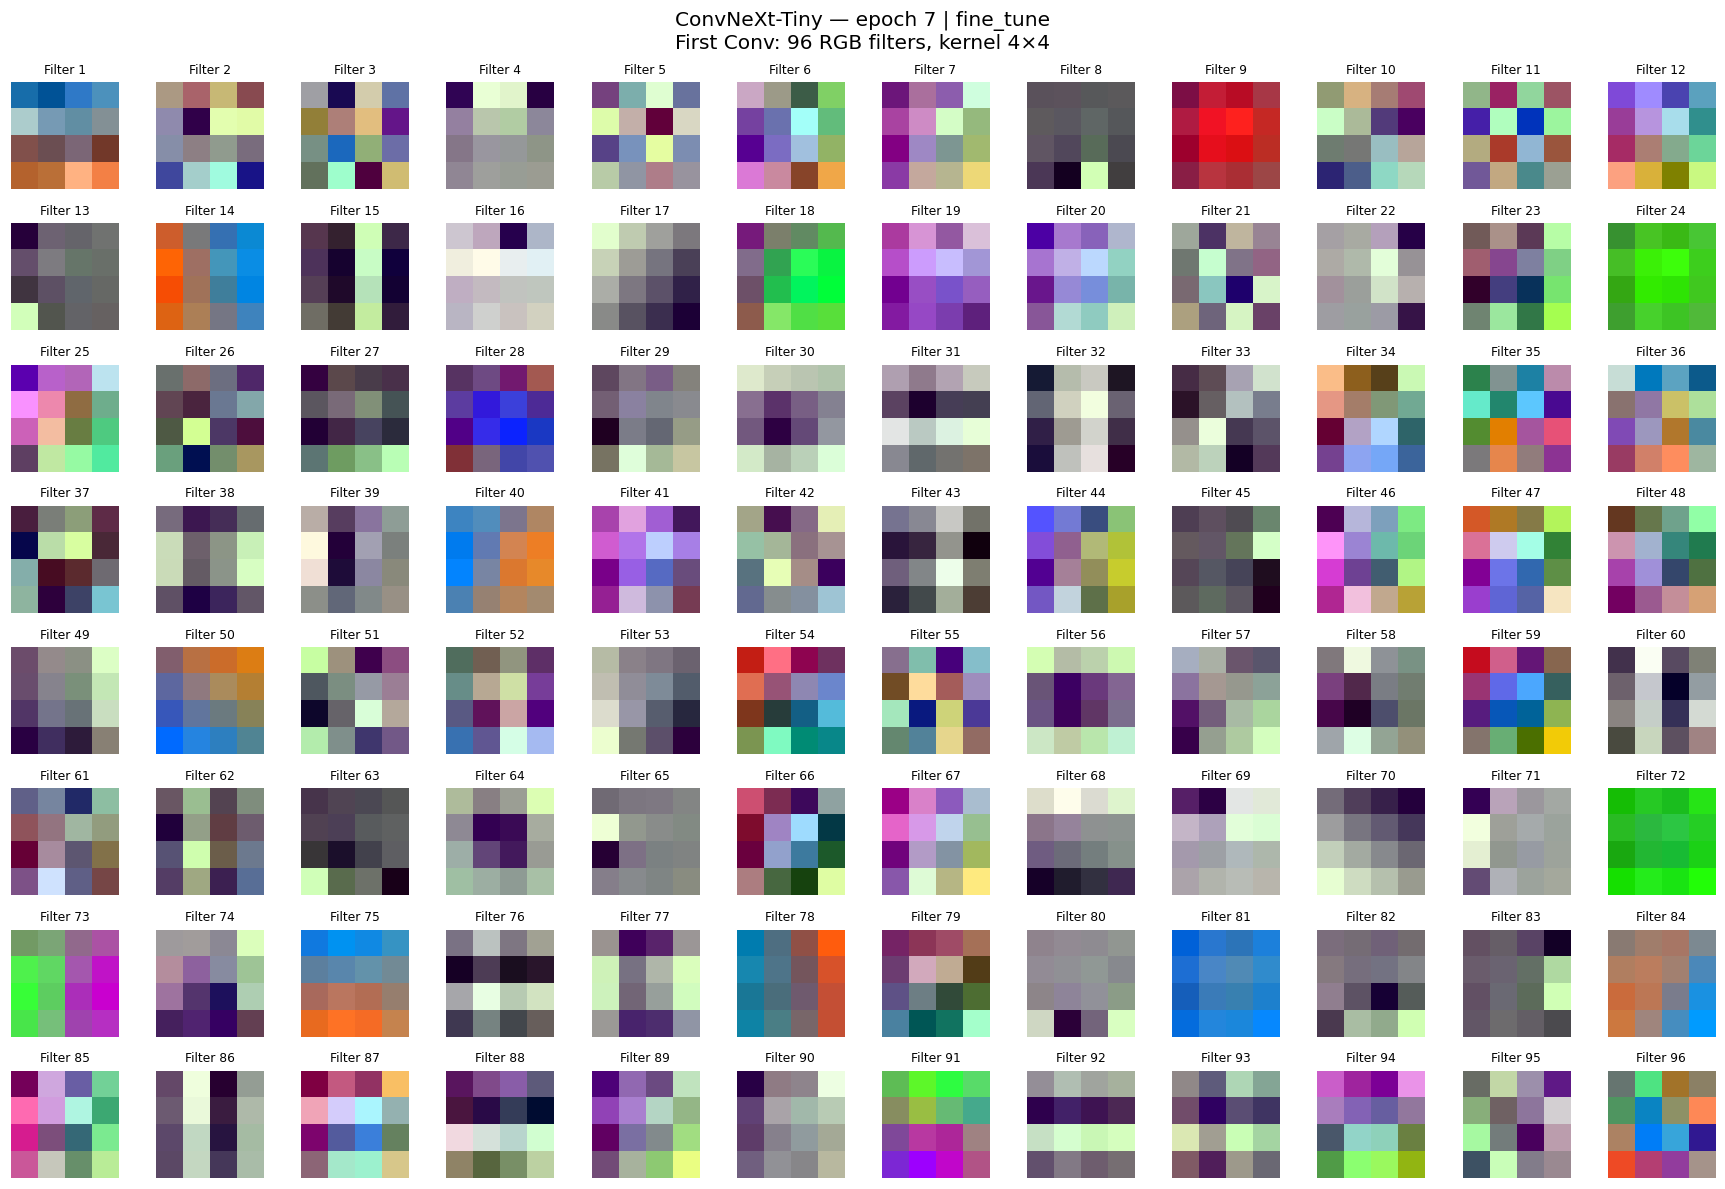

In [38]:
filters = selected_model.features[0][0].weight.detach().cpu().permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(8, 12, figsize=(16, 11))

for i, ax in enumerate(axes.flat):
    values = filters[i]
    ax.imshow(
        (values - values.min()) / (values.max() - values.min() + 1e-8),
        interpolation="nearest"
    )
    ax.set_title(f"Filter {i + 1}", fontsize=8)
    ax.axis("off")

fig.suptitle(f"{caption}\nFirst Conv: 96 RGB filters, kernel 4×4")
fig.tight_layout()
fig.savefig(analysis_dir / "conv1_filters.png", dpi=300)
plt.show()
plt.close(fig)

## Feature maps lớp tích chập đầu tiên

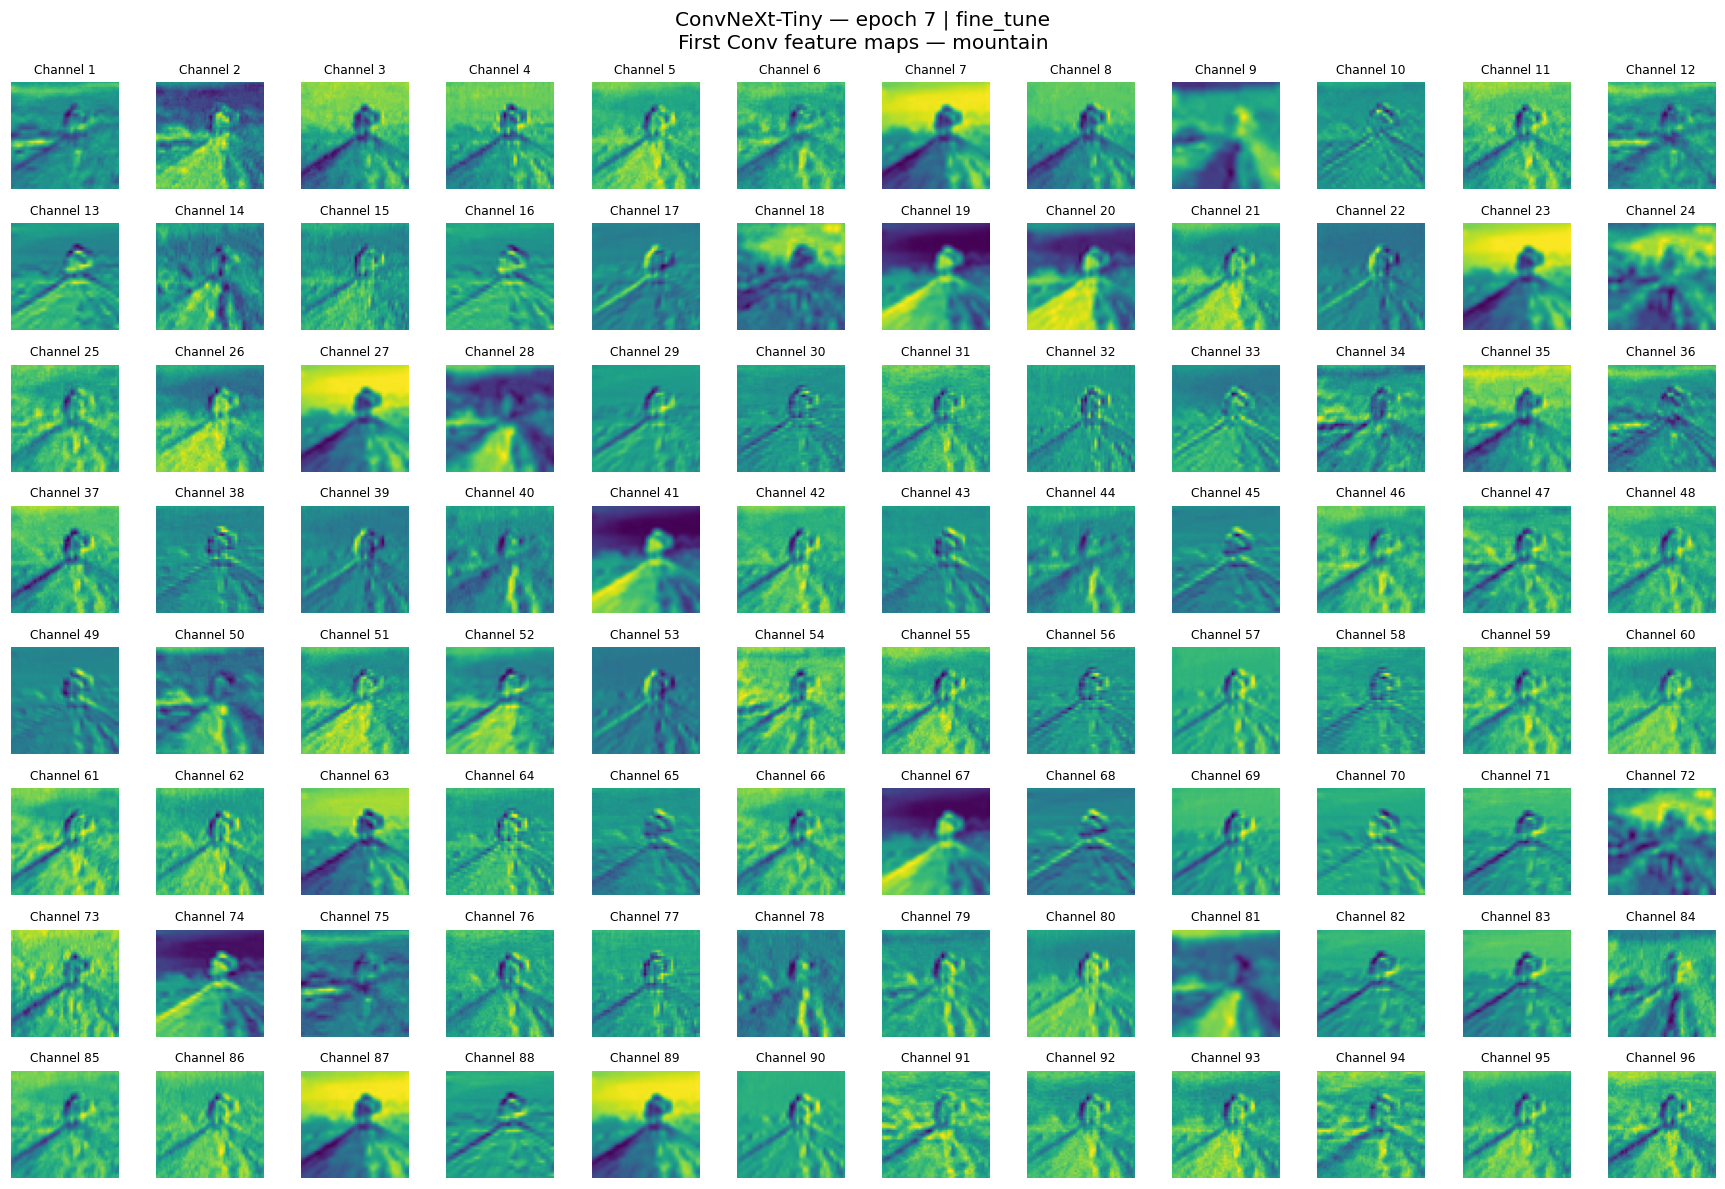

In [39]:
position = int(visual_samples["feature_map_position"])
global_id = int(splits["test_idx"][position])
image = pre_trans(Image.fromarray(raw_images[global_id])).unsqueeze(0).to(device)

with torch.inference_mode():
    maps = selected_model.features[0][0](image)[0].cpu().numpy()

fig, axes = plt.subplots(8, 12, figsize=(16, 11))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i], cmap="viridis")
    ax.set_title(f"Channel {i + 1}", fontsize=8)
    ax.axis("off")

fig.suptitle(
    f"{caption}\nFirst Conv feature maps — {class_names[raw_labels[global_id]]}"
)
fig.tight_layout()
fig.savefig(analysis_dir / "feature_maps_conv1.png", dpi=300)
plt.show()
plt.close(fig)

## 9. Trích xuất Feature Vector (768 chiều) & Giảm chiều t-SNE 2D


In [40]:
feature_extractor = nn.Sequential(
    selected_model.features, selected_model.avgpool,
    selected_model.classifier[0], selected_model.classifier[1]
).eval()

parts = []
with torch.inference_mode():
    for images, _ in test_loader:
        parts.append(feature_extractor(images.to(device)).cpu().numpy())
test_features = np.concatenate(parts)

np.savez_compressed(
    analysis_dir / "test_features.npz", features=test_features,
    labels=test_labels, global_indices=splits["test_idx"],
    checkpoint_sha256=checkpoint_sha256
)
test_features.shape

(10000, 768)

### Trích feature vector toàn bộ Test — CNN 256D; ConvNeXt 768D


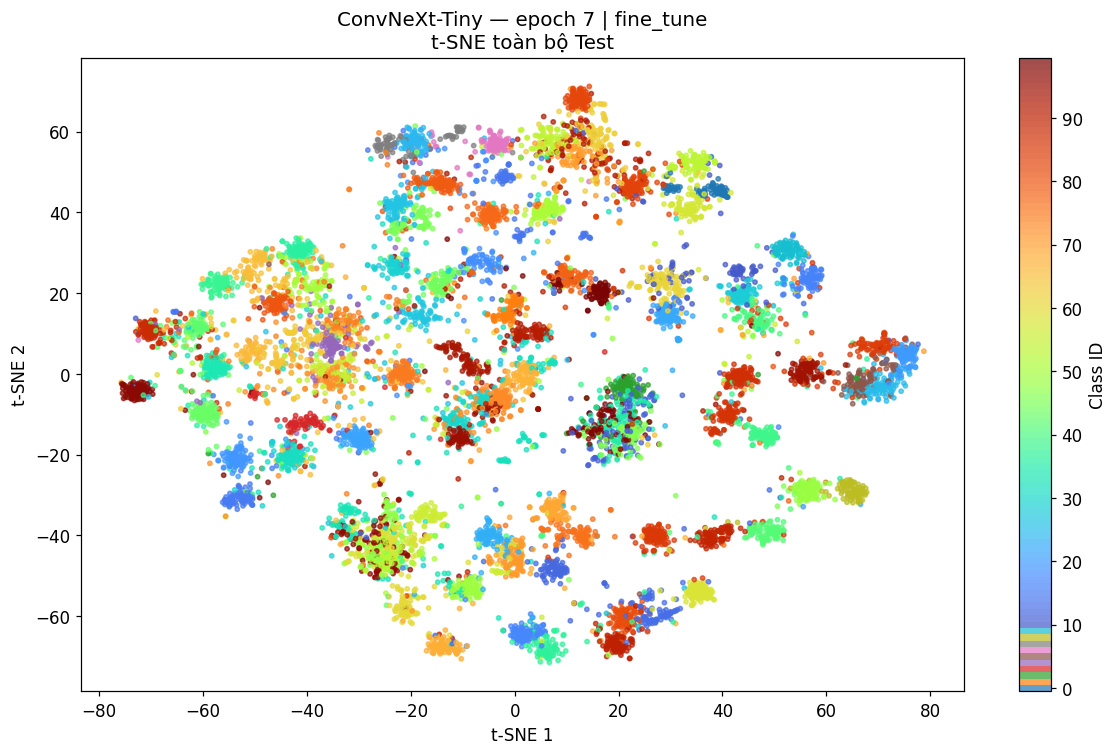

In [41]:
import inspect
from matplotlib.colors import ListedColormap

colors = plt.get_cmap("turbo")(np.linspace(0, 1, len(class_names)))
colors[:10] = plt.get_cmap("tab10")(np.arange(10))
tsne_params = dict(
    n_components=2, perplexity=min(30, len(test_labels) - 1),
    learning_rate=200, init="pca", random_state=SEED
)
iteration_key = "max_iter" if "max_iter" in inspect.signature(TSNE).parameters else "n_iter"
tsne_params[iteration_key] = TSNE_MAX_ITER
projection = TSNE(**tsne_params).fit_transform(test_features)

np.savez_compressed(
    analysis_dir / "tsne_all_test.npz", coordinates=projection,
    labels=test_labels, global_indices=splits["test_idx"],
    checkpoint_sha256=checkpoint_sha256
)
fig, ax = plt.subplots(figsize=(11, 7))
scatter = ax.scatter(
    projection[:, 0], projection[:, 1], c=test_labels,
    cmap=ListedColormap(colors), vmin=-0.5,
    vmax=len(class_names) - 0.5, s=8, alpha=0.7
)
fig.colorbar(scatter, ax=ax, ticks=np.arange(0, len(class_names), 10), label="Class ID")
ax.set(title=f"{caption}\nt-SNE toàn bộ Test", xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.tight_layout()
fig.savefig(analysis_dir / "tsne_all_test.png", dpi=300)
plt.show()
plt.close(fig)

## t-SNE chi tiết 10 lớp

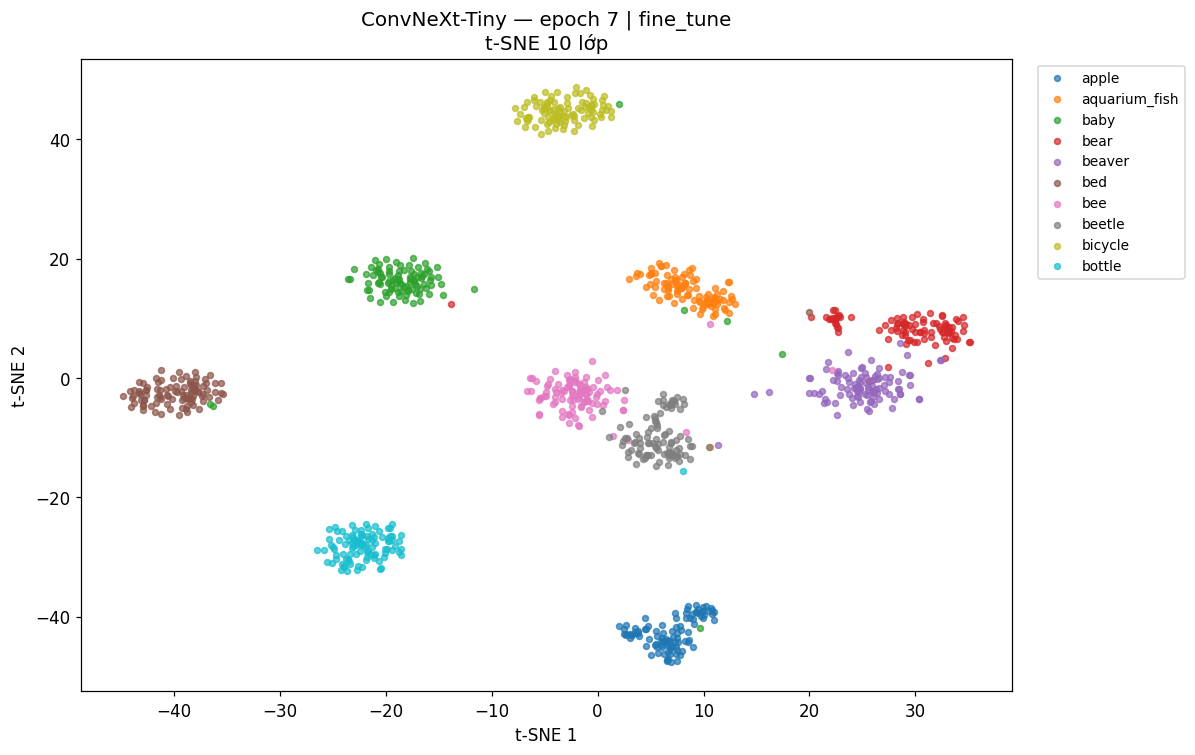

In [42]:
positions = np.asarray(visual_samples["tsne_detail_positions"], dtype=int)
tsne_params["perplexity"] = min(30, len(positions) - 1)
detail = TSNE(**tsne_params).fit_transform(test_features[positions])
labels = test_labels[positions]

np.savez_compressed(
    analysis_dir / "tsne_detail_classes.npz", coordinates=detail,
    labels=labels, global_indices=splits["test_idx"][positions],
    checkpoint_sha256=checkpoint_sha256
)
fig, ax = plt.subplots(figsize=(11, 7))
for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(
        detail[mask, 0], detail[mask, 1], color=colors[class_id],
        s=15, alpha=0.7, label=class_names[class_id]
    )

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.set(title=f"{caption}\nt-SNE 10 lớp", xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.tight_layout()
fig.savefig(analysis_dir / "tsne_detail_classes.png", dpi=300)
plt.show()
plt.close(fig)

### Dự đoán cùng 30 ảnh Test


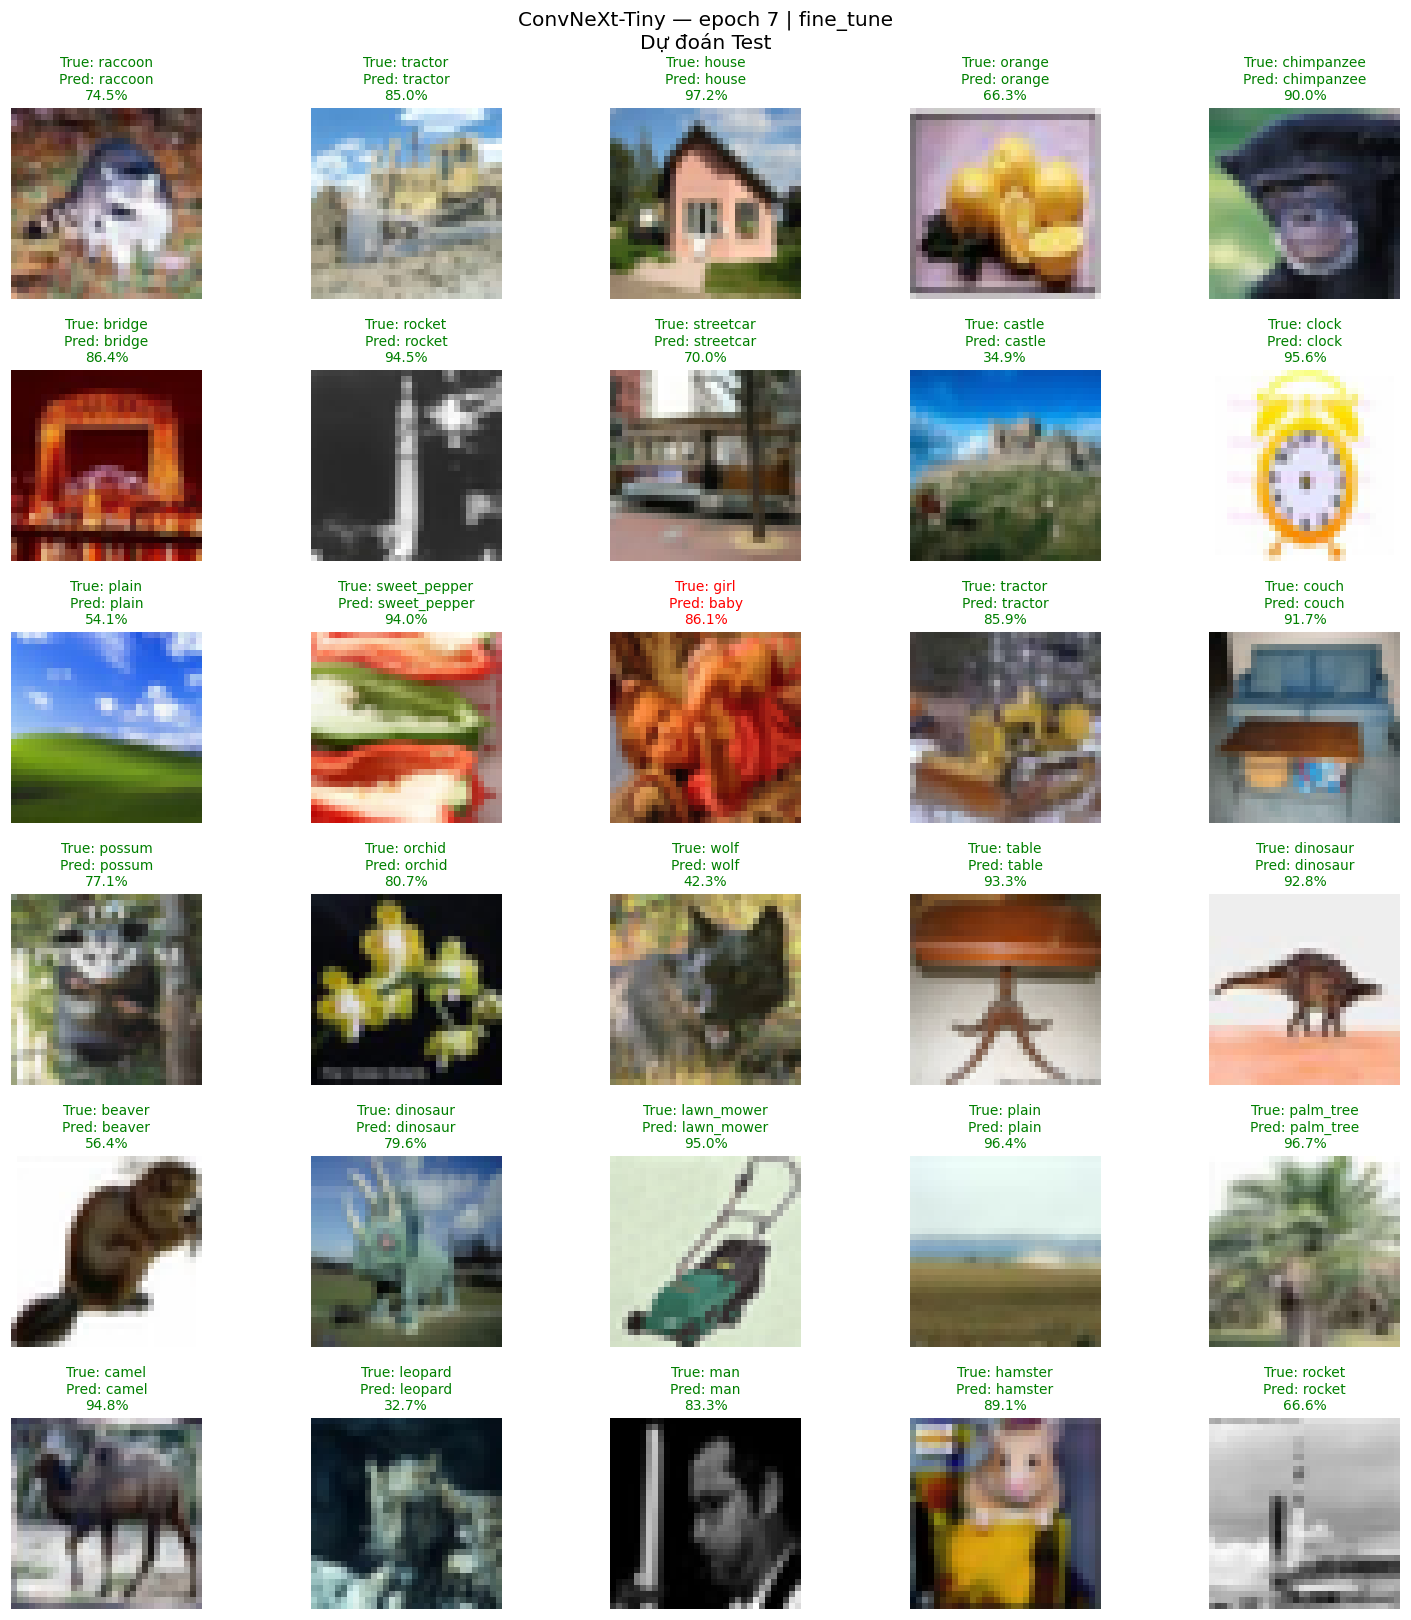

In [43]:
positions = np.asarray(visual_samples["prediction_positions"], dtype=int)
predicted = test_probabilities.argmax(1)
confidence = test_probabilities.max(1)
fig, axes = plt.subplots(6, 5, figsize=(14, 15))

for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < len(positions):
        p = positions[i]
        ax.imshow(raw_images[splits["test_idx"][p]])
        ax.set_title(
            f"True: {class_names[test_labels[p]]}\n"
            f"Pred: {class_names[predicted[p]]}\n{confidence[p]:.1%}",
            fontsize=9, color="green" if test_labels[p] == predicted[p] else "red"
        )

fig.suptitle(f"{caption}\nDự đoán Test")
fig.tight_layout()
fig.savefig(analysis_dir / "sample_predictions.png", dpi=300)
plt.show()
plt.close(fig)

### Confusion matrix và classification report


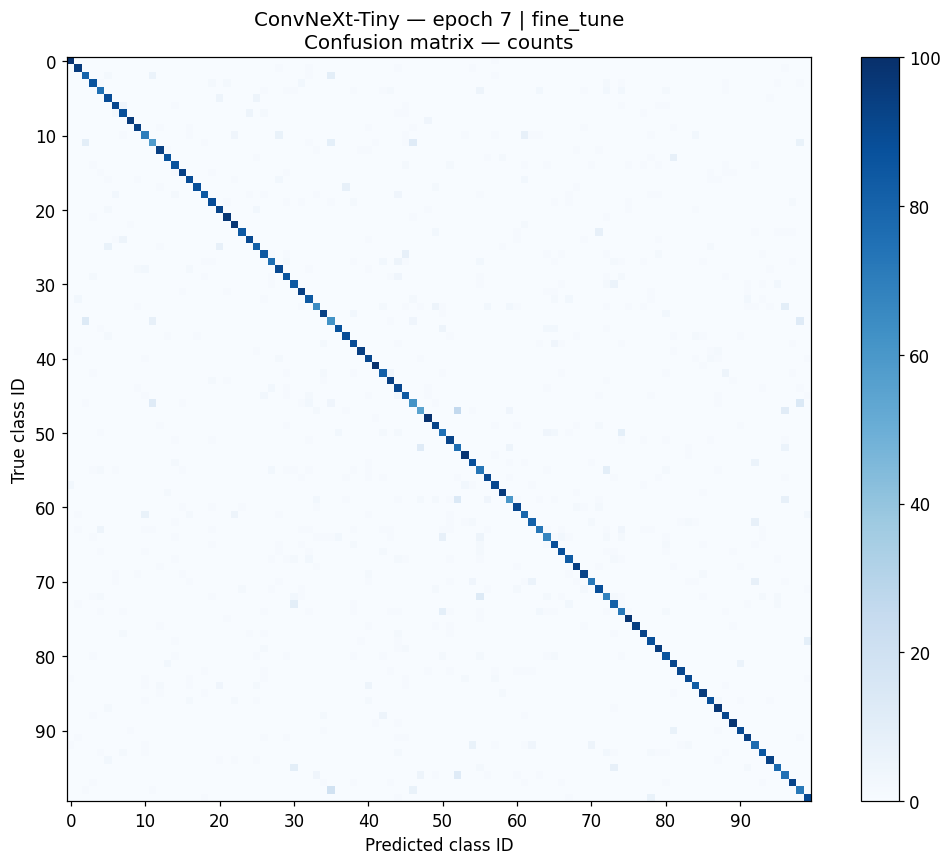

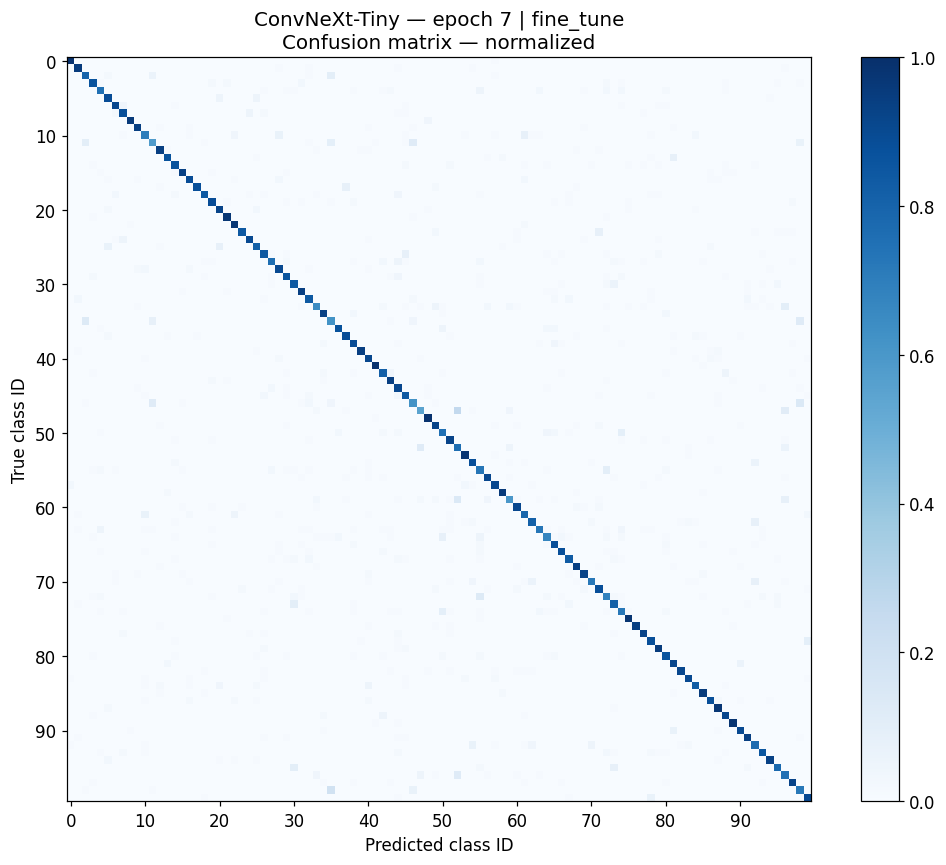

,precision,recall,f1-score,support
macro avg,0.8599,0.8579,0.8574,10000.0
weighted avg,0.8599,0.8579,0.8574,10000.0


In [44]:
matrix = confusion_matrix(test_labels, predicted, labels=np.arange(len(class_names)))
normalized = np.divide(
    matrix, matrix.sum(1, keepdims=True),
    out=np.zeros_like(matrix, dtype=float), where=matrix.sum(1, keepdims=True) != 0
)

for name, values, maximum in [
    ("counts", matrix, int(matrix.sum(1).max())),
    ("normalized", normalized, 1)
]:
    pd.DataFrame(values, index=class_names, columns=class_names).to_csv(
        analysis_dir / f"confusion_{name}.csv"
    )
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)
    ticks = np.arange(0, len(class_names), 10)
    ax.set_xticks(ticks, ticks)
    ax.set_yticks(ticks, ticks)
    ax.set(
        title=f"{caption}\nConfusion matrix — {name}",
        xlabel="Predicted class ID", ylabel="True class ID"
    )
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(analysis_dir / f"confusion_{name}.png", dpi=300)
    plt.show()
    plt.close(fig)

report = classification_report(
    test_labels, predicted, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)
report_table = pd.DataFrame(report).T.drop(index="accuracy", errors="ignore")
report_table.to_csv(analysis_dir / "classification_report.csv")
display(report_table.loc[["macro avg", "weighted avg"]].round(4))

## Tải ZIP đầy đủ 

In [48]:
from pathlib import Path
from IPython.display import display, FileLink

# Tìm chính xác tệp ZIP đã nén trong thư mục run_dir
zip_files = list(Path(run_dir).glob("*.zip"))

if zip_files:
    # Lấy tệp zip mới nhất vừa tạo
    latest_zip = max(zip_files, key=lambda p: p.stat().st_mtime)
    print(f"Đã tìm thấy tệp nén: {latest_zip.name} ({latest_zip.stat().st_size / (1024**2):.2f} MB)")
    display(FileLink(str(latest_zip)))
else:
    print("Không tìm thấy tệp ZIP nào. Vui lòng chạy lại cell nén tệp trước đó!")

Đã tìm thấy tệp nén: ConvNeXt_epoch_007_BaoCao.zip (133.92 MB)


/kaggle/working/cifar100_unified/convnext_tiny_20261023T133653Z_1f8ef0/ConvNeXt_epoch_007_BaoCao.zip

In [46]:
import shutil

for name in (
    "training_curves.png", "history.csv", "config.json",
    "class_names.csv", "split_indices.npz", "visual_indices.npz"
):
    source = run_dir / name
    if source.is_file():
        shutil.copy2(source, analysis_dir / name)

shutil.copy2(MODEL_PATH, analysis_dir / "best.pth")
zip_path = shutil.make_archive(
    str(run_dir / f"ConvNeXt_epoch_{SELECTED_EPOCH:03d}_BaoCao"),
    "zip", str(analysis_dir)
)
display(FileLink(zip_path))

/kaggle/working/cifar100_unified/convnext_tiny_20261023T133653Z_1f8ef0/ConvNeXt_epoch_007_BaoCao.zip